Original Dataset:
      Hours Studied  Previous Scores  Sleep Hours  \
0                 7               99            9   
1                 4               82            4   
2                 8               51            7   
3                 5               52            5   
4                 7               75            8   
...             ...              ...          ...   
9995              1               49            4   
9996              7               64            8   
9997              6               83            8   
9998              9               97            7   
9999              7               74            8   

      Sample Question Papers Practiced  
0                                    1  
1                                    2  
2                                    2  
3                                    2  
4                                    5  
...                                ...  
9995                                 2  
9996             

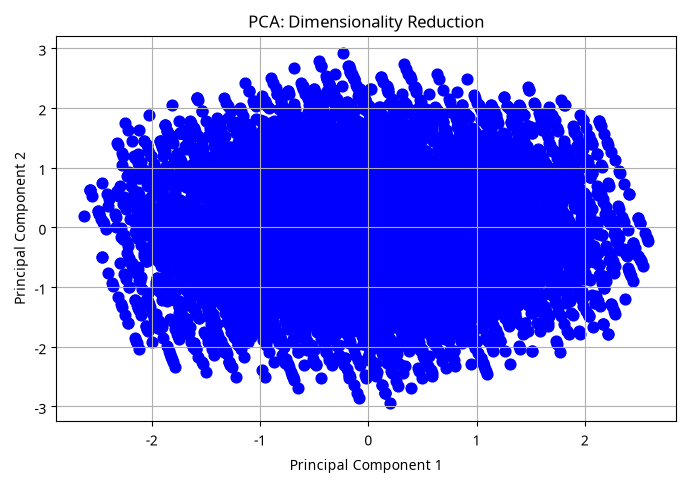

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

df = pd.read_csv("Student_Performance.csv")[["Hours Studied", "Previous Scores", "Sleep Hours", "Sample Question Papers Practiced"]]

print("Original Dataset:")
print(df)
print("\nStatistical Summary:")
print(df.describe())

scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(df)

normalized_df = pd.DataFrame(normalized_data, columns=df.columns)

print("Normalized Dataset:")
print(normalized_df.round(2))

print("\nMinimum values:")
print(normalized_df.min())

print("\nMaximum values:")
print(normalized_df.max())

scaler = StandardScaler()

standardized_data = scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("Standardized Dataset:")
print(standardized_df.round(2))

print("\nMean of each feature:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of each feature:")
print(standardized_df.std(ddof=0).round(2))

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Data:")
print(pca_df.round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()